In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:

# ============================================================
# Fourier-Galerkin eigenvalues for L_h (linearization around rho_h^pert)
# ============================================================


Gamma = 1.0
F = 0.5
alpha = 0.12                 # alpha = gamma/2 - Gamma
gamma = 2*(Gamma + alpha)

N = 32                       # Fourier cutoff: modes n=-N..N, excluding n=0
h_values = np.linspace(0.0, 0.4, 12)   # for overlay plots
h_small  = np.array([0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5])  # for error scaling

# ============================================================
# Fourier helpers
# ============================================================

def build_modes(N):
    """Fourier modes kept in the truncation: -N..N excluding 0."""
    return np.array([n for n in range(-N, N + 1) if n != 0], dtype=int)

def J_mode(n):
    """I[e_n] = J_n e_n (only nonzero for n=±1)."""
    if n == 1:
        return -1j * np.pi
    elif n == -1:
        return 1j * np.pi
    return 0.0 + 0.0j

def rho1_coeffs(alpha, F):
    """
    rho1(theta) = A cos(theta) + B sin(theta) = c1 e^{iθ} + c_-1 e^{-iθ}.
    Return Fourier coeffs on {-1,0,1}.
    """
    denom = alpha**2 + F**2
    A = -(1/(2*np.pi)) * alpha / denom
    B =  (1/(2*np.pi)) * F     / denom
    c1  = (A - 1j*B)/2
    cm1 = (A + 1j*B)/2
    return {-1: cm1, 0: 0.0+0.0j, 1: c1}

def rhoh_coeffs(h, Gamma, gamma, F):
    """rho_h^pert = 1/(2π) + h rho1, in Fourier coeffs on {-1,0,1}."""
    a = gamma/2 - Gamma
    r1 = rho1_coeffs(a, F)
    return {-1: h*r1[-1], 0: 1/(2*np.pi), 1: h*r1[1]}

def Ih_from_rho_coeffs(rho_coeffs):
    """Compute Fourier coeffs of I[rho_h] (only ±1 can be nonzero)."""
    out = {}
    for m, c in rho_coeffs.items():
        Jm = J_mode(m)
        if abs(Jm) > 0:
            out[m] = Jm * c
    return out

def q_coeffs(h, Gamma, gamma, F):
    """
    q(theta) = F - h sin(theta) - gamma I[rho_h](theta)
    Return Fourier coeffs on {-1,0,1}.
    """
    # sin(theta) = (e^{iθ} - e^{-iθ})/(2i) => coeffs: s_1=-i/2, s_-1=+i/2
    sin_coeff = {1: -0.5j, -1: 0.5j}

    rhoh = rhoh_coeffs(h, Gamma, gamma, F)
    Irho = Ih_from_rho_coeffs(rhoh)

    q = {0: F + 0j, -1: 0j, 1: 0j}
    for m in (-1, 1):
        q[m] += -h * sin_coeff[m]
        q[m] += -gamma * Irho.get(m, 0j)
    return q

def build_Lh_matrix(h, Gamma, gamma, F, N):
    """
    Build Fourier-Galerkin matrix for L_h around rho_h^pert.

    Operator:
      L_h η = -∂θ(q_h η) + gamma ∂θ( rho_h I[η] ) + Gamma ∂θ^2 η
    where q_h = F - h sinθ - gamma I[rho_h].
    """
    modes = build_modes(N)
    idx = {n:i for i,n in enumerate(modes)}
    M = np.zeros((len(modes), len(modes)), dtype=complex)

    rhoh = rhoh_coeffs(h, Gamma, gamma, F)  # Fourier modes -1,0,1
    q = q_coeffs(h, Gamma, gamma, F)        # Fourier modes -1,0,1

    for n in modes:
        col = idx[n]

        # Term 1: -∂θ(q * e_n)
        # q has modes m ∈ {-1,0,1}, so q e_n lives in modes k=n+m
        for m in (-1, 0, 1):
            k = n + m
            if k == 0 or abs(k) > N:
                continue
            M[idx[k], col] += -(1j*k) * q.get(m, 0j)

        # Term 2: +Gamma ∂θ^2 e_n = -Gamma n^2 e_n
        M[idx[n], col] += -Gamma * n**2

        # Term 3: +gamma ∂θ( rho_h * I[e_n] )
        # I[e_n] = J_n e_n, only for n=±1
        Jn = J_mode(n)
        if abs(Jn) > 0:
            for m in (-1, 0, 1):
                k = n + m
                if k == 0 or abs(k) > N:
                    continue
                M[idx[k], col] += gamma * (1j*k) * rhoh.get(m, 0j) * Jn

    return M, modes

# ============================================================
# Patched perturbative formula: lambda(h)=lambda0+h^2 lambda2 + O(h^3)
# ============================================================

def lambda2_corrected_plus(Gamma, gamma, F):
    """
    Corrected matrix-derived lambda2 for the n=+1 branch:
      lambda2 = -(A12 * B21)/(mu2 - mu1)
    where A12 is coefficient of e2 in L1 e1, and B21 is coefficient of e1 in L1 e2.
    """
    a = gamma/2 - Gamma
    mu1 = a - 1j*F
    mu2 = -4*Gamma - 2j*F

    # Derived couplings:
    A12 = (F - 1j*(2*Gamma + a)) / (F + 1j*a)                # e1 -> e2 under L1
    B21 = -1j * (Gamma - 1j*F) / (2*(F - 1j*a))              # e2 -> e1 under L1

    return -(A12 * B21) / (mu2 - mu1)

def lambda_plus_pert(h, Gamma, gamma, F):
    a = gamma/2 - Gamma
    lam0 = a - 1j*F
    lam2 = lambda2_corrected_plus(Gamma, gamma, F)
    return lam0 + (h**2) * lam2

# ============================================================
# Branch tracking
# ============================================================

def track_branch(h_values, Gamma, gamma, F, N):
    """
    Track the eigenvalue branch starting at the eigenvalue closest to alpha - iF at h=0,
    then continue by nearest neighbor in the complex plane as h increases.
    """
    h_values = np.array(h_values, dtype=float)
    tracked = np.zeros_like(h_values, dtype=complex)

    target0 = (gamma/2 - Gamma) - 1j*F
    M0, _ = build_Lh_matrix(h_values[0], Gamma, gamma, F, N)
    eigs0 = np.linalg.eigvals(M0)
    tracked[0] = eigs0[np.argmin(np.abs(eigs0 - target0))]

    for j in range(1, len(h_values)):
        M, _ = build_Lh_matrix(h_values[j], Gamma, gamma, F, N)
        eigs = np.linalg.eigvals(M)
        tracked[j] = eigs[np.argmin(np.abs(eigs - tracked[j-1]))]

    return tracked

# ============================================================
# Run computations
# ============================================================

lam_num  = track_branch(h_values, Gamma, gamma, F, N)
lam_pert = np.array([lambda_plus_pert(h, Gamma, gamma, F) for h in h_values])

hs = np.concatenate(([0.0], h_small))
lam_num_small  = track_branch(hs, Gamma, gamma, F, N)
lam_pert_small = np.array([lambda_plus_pert(h, Gamma, gamma, F) for h in hs])
err_small = np.abs(lam_num_small - lam_pert_small)

lam2_corr = lambda2_corrected_plus(Gamma, gamma, F)

print("Parameters:")
print(f"  Gamma={Gamma}, F={F}, alpha={alpha}, gamma={gamma}, N={N}")
print(f"Corrected lambda2 = {lam2_corr.real:+.12e} {lam2_corr.imag:+.12e}j")
print("\nSmall-h check (h, |error|):")
for h, e in zip(hs[:6], err_small[:6]):
    print(f"  h={h: .3e}: {e:.3e}")


Parameters:
  Gamma=1.0, F=0.5, alpha=0.12, gamma=2.24, N=32
Corrected lambda2 = -1.041296270383e+00 +3.834101087501e-01j

Small-h check (h, |error|):
  h= 0.000e+00: 0.000e+00
  h= 5.000e-02: 6.771e-07
  h= 1.000e-01: 1.085e-05
  h= 1.500e-01: 5.510e-05
  h= 2.000e-01: 1.748e-04
  h= 3.000e-01: 8.954e-04


Plots

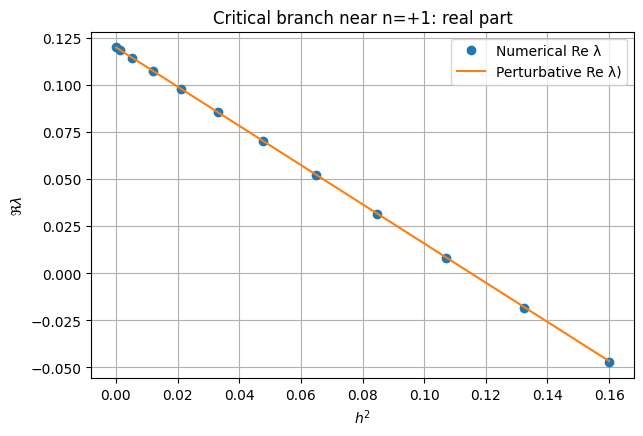

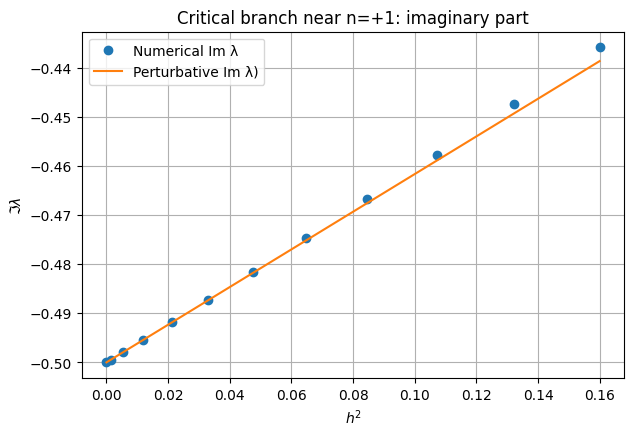

In [3]:

# ============================================================

# 1) Real part vs h^2
plt.figure(figsize=(7,4.5))
plt.plot(h_values**2, lam_num.real, 'o', label='Numerical Re λ')
plt.plot(h_values**2, lam_pert.real, '-', label='Perturbative Re λ)')
plt.xlabel(r'$h^2$')
plt.ylabel(r'$\Re \lambda$')
plt.title('Critical branch near n=+1: real part')
plt.grid(True)
plt.legend()
plt.show()

# 2) Imag part vs h^2
plt.figure(figsize=(7,4.5))
plt.plot(h_values**2, lam_num.imag, 'o', label='Numerical Im λ')
plt.plot(h_values**2, lam_pert.imag, '-', label='Perturbative Im λ)')
plt.xlabel(r'$h^2$')
plt.ylabel(r'$\Im \lambda$')
plt.title('Critical branch near n=+1: imaginary part')
plt.grid(True)
plt.legend()
plt.show()


Put the plots together

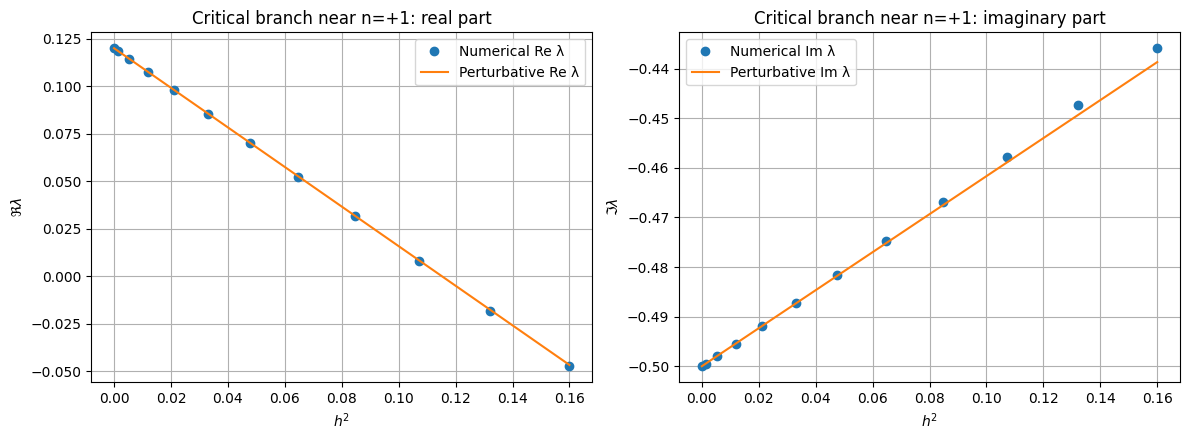

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) Real part vs h^2
axes[0].plot(h_values**2, lam_num.real, 'o', label='Numerical Re λ')
axes[0].plot(h_values**2, lam_pert.real, '-', label='Perturbative Re λ')
axes[0].set_xlabel(r'$h^2$')
axes[0].set_ylabel(r'$\Re \lambda$')
axes[0].set_title('Critical branch near n=+1: real part')
axes[0].grid(True)
axes[0].legend()

# 2) Imag part vs h^2
axes[1].plot(h_values**2, lam_num.imag, 'o', label='Numerical Im λ')
axes[1].plot(h_values**2, lam_pert.imag, '-', label='Perturbative Im λ')
axes[1].set_xlabel(r'$h^2$')
axes[1].set_ylabel(r'$\Im \lambda$')
axes[1].set_title('Critical branch near n=+1: imaginary part')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

Finds and plots $\gamma_c$

In [4]:
# ============================================================
# Root-finding for critical gamma
# ============================================================

def lambda2_corrected_plus_from_alpha(Gamma, alpha, F):
    """
    Same lambda2 formula, but parameterized directly by alpha.
    """
    gamma = 2*(Gamma + alpha)
    mu1 = alpha - 1j*F
    mu2 = -4*Gamma - 2j*F

    A12 = (F - 1j*(2*Gamma + alpha)) / (F + 1j*alpha)
    B21 = -1j * (Gamma - 1j*F) / (2*(F - 1j*alpha))

    return -(A12 * B21) / (mu2 - mu1)

def lambda_plus_pert_alpha(h, Gamma, alpha, F):
    lam0 = alpha - 1j*F
    lam2 = lambda2_corrected_plus_from_alpha(Gamma, alpha, F)
    return lam0 + (h**2) * lam2

def re_lambda_pert_gamma(gamma, h, Gamma, F):
    alpha = gamma/2 - Gamma
    return lambda_plus_pert_alpha(h, Gamma, alpha, F).real

def tracked_eigenvalue_for_gamma(h, Gamma, gamma, F, N):
    """
    Return the tracked critical eigenvalue at fixed h and gamma.
    Since this is a single parameter value, we pick the eigenvalue
    closest to alpha - iF as the continuation of the n=+1 branch.
    """
    alpha = gamma/2 - Gamma
    target = alpha - 1j*F
    M, _ = build_Lh_matrix(h, Gamma, gamma, F, N)
    eigs = np.linalg.eigvals(M)
    return eigs[np.argmin(np.abs(eigs - target))]

def re_lambda_num_gamma(gamma, h, Gamma, F, N):
    return tracked_eigenvalue_for_gamma(h, Gamma, gamma, F, N).real

def bisect_root(f, a, b, tol=1e-10, maxiter=100):
    fa = f(a)
    fb = f(b)
    if fa == 0:
        return a
    if fb == 0:
        return b
    if fa * fb > 0:
        raise ValueError(f"Root not bracketed: f(a)={fa}, f(b)={fb}")

    for _ in range(maxiter):
        c = 0.5*(a+b)
        fc = f(c)
        if abs(fc) < tol or abs(b-a) < tol:
            return c
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return 0.5*(a+b)

def find_gamma_c_pert(h, Gamma, F, gamma_guess=None, width=0.5):
    """
    Solve Re lambda_pert(h,gamma)=0 by bisection.
    """
    if gamma_guess is None:
        gamma_guess = 2*Gamma

    f = lambda g: re_lambda_pert_gamma(g, h, Gamma, F)

    a = gamma_guess - width
    b = gamma_guess + width

    # expand bracket if needed
    for _ in range(20):
        fa, fb = f(a), f(b)
        if fa * fb <= 0:
            return bisect_root(f, a, b)
        width *= 1.5
        a = gamma_guess - width
        b = gamma_guess + width

    raise RuntimeError("Could not bracket perturbative gamma_c")

def find_gamma_c_num(h, Gamma, F, N, gamma_guess=None, width=0.5):
    """
    Solve Re lambda_num(h,gamma)=0 by bisection.
    """
    if gamma_guess is None:
        gamma_guess = 2*Gamma

    f = lambda g: re_lambda_num_gamma(g, h, Gamma, F, N)

    a = gamma_guess - width
    b = gamma_guess + width

    for _ in range(20):
        fa, fb = f(a), f(b)
        if fa * fb <= 0:
            return bisect_root(f, a, b)
        width *= 1.5
        a = gamma_guess - width
        b = gamma_guess + width

    raise RuntimeError("Could not bracket numerical gamma_c")

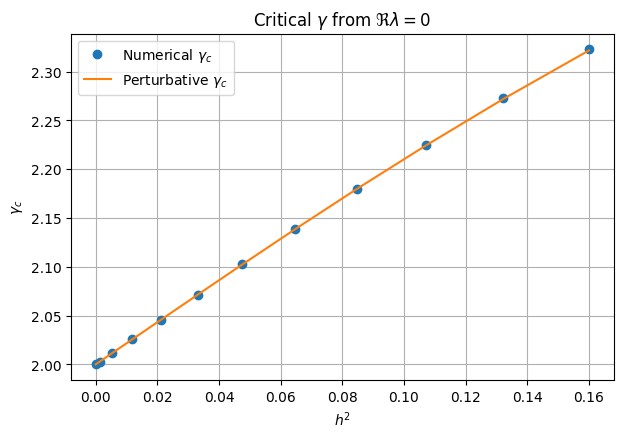

In [5]:
# ============================================================
# Critical gamma vs h
# ============================================================

h_crit_vals = np.linspace(0.0, 0.4, 12)

gamma_c_num = []
gamma_c_pert = []
gamma_c_explicit = []

for h in h_crit_vals:
    # numerical root
    gc_num = find_gamma_c_num(h, Gamma, F, N, gamma_guess=2*Gamma, width=0.4)
    gamma_c_num.append(gc_num)

    # perturbative root from Re(lambda_pert)=0
    gc_pert = find_gamma_c_pert(h, Gamma, F, gamma_guess=2*Gamma, width=0.4)
    gamma_c_pert.append(gc_pert)

    # explicit O(h^2) threshold using alpha_c = -h^2 Re lambda2(0)
    lam2_at_alpha0 = lambda2_corrected_plus_from_alpha(Gamma, 0.0, F)
    gc_exp = 2*Gamma - 2*(h**2)*lam2_at_alpha0.real
    gamma_c_explicit.append(gc_exp)

gamma_c_num = np.array(gamma_c_num)
gamma_c_pert = np.array(gamma_c_pert)
gamma_c_explicit = np.array(gamma_c_explicit)

plt.figure(figsize=(7,4.5))
plt.plot(h_crit_vals**2, gamma_c_num, 'o', label='Numerical $\\gamma_c$')
plt.plot(h_crit_vals**2, gamma_c_pert, '-', label='Perturbative $\\gamma_c$')
#plt.plot(h_crit_vals**2, gamma_c_explicit, '--', label='Explicit $O(h^2)$ threshold')
plt.xlabel(r'$h^2$')
plt.ylabel(r'$\gamma_c$')
plt.title(r'Critical $\gamma$ from $\Re\lambda=0$')
plt.grid(True)
plt.legend()
plt.show()
